6 November 2026 Alison Sills

Testing, at a minimum level, how SeBa in Amuse evolves stars that are not on the ZAMS at the moment the evolution begins. 

There are two necessary cases where this needs to work -- a Torch restart, or when we want to artifically modify the properties of a star and then have it pick up its evolution with the new properties.

In [46]:
from amuse.units import units
from amuse.datamodel import Particles, Particle
from amuse.community.seba import Seba
import numpy as np
from matplotlib import pyplot as plt
from amuse.io import write_set_to_file, read_set_from_file

This routine takes a star with properties provided and evolves it in SeBa from t_start to t_end, returning snapshots saved every t_step.

In [57]:
def evolve_star(
    mass=1.0,
    relative_mass=1.0,
    stellar_type=1,
    age=0,
    relative_age=0,
    core_mass=0,
    COcore_mass=0,
    t_start=0,
    t_end=1,
    t_step=0.1,
):

    star=Particle(
        mass=mass | units.Msun,
        relative_mass=relative_mass |units.Msun,
        stellar_type = stellar_type |units.stellar_type,
        age=age |units.Myr,
        relative_age=relative_age | units.Myr,
        core_mass=core_mass |units.MSun,
        COcore_mass=COcore_mass |units.MSun,
    )


    stellar=Seba()
    
    stellar.particles.add_particle(star)

    snapshots=Particles()

    t=t_start |units.Myr
    
    while t < t_end | units.Myr:
        t+= t_step |units.Myr
        stellar.evolve_model(t)
        snapshots.add_particles(stellar.particles)

    stellar.stop()

    return snapshots


This routine is almost the same as the above, but more closely follows the minimal stellar evolution example from Amuse -- we cannot specify a start time. 

In [58]:
def evolve_star_no_tstart(
    mass=1.0,
    relative_mass=1.0,
    stellar_type=1,
    age=0,
    relative_age=0,
    core_mass=0,
    COcore_mass=0,
    t_end=1,
    t_step=0.1,
):

    star=Particle(
        mass=mass | units.Msun,
        relative_mass=relative_mass |units.Msun,
        stellar_type = stellar_type |units.stellar_type,
        age=age |units.Myr,
        relative_age=relative_age | units.Myr,
        core_mass=core_mass |units.MSun,
        COcore_mass=COcore_mass |units.MSun,
    )


    stellar=Seba()
    
    stellar.particles.add_particle(star)

    snapshots=Particles()

    timestep=t_step |units.Myr
    
    while stellar.model_time < t_end | units.Myr:
        stellar.evolve_model(stellar.model_time + timestep)
        snapshots.add_particles(stellar.particles)

    stellar.stop()

    return snapshots

We evolve a 40 MSun star as a baseline. 
We also evolve the same star to 3 Myr (part-way through the main sequence), and will use information about that star to start subsequent evolution runs. 

In [59]:
baseline=evolve_star(mass=40,relative_mass=40,stellar_type=1,age=0,relative_age=0,core_mass=0,COcore_mass=0,t_start=0,t_end=6,t_step=0.1)

first_part=evolve_star(mass=40,relative_mass=40,stellar_type=1,age=0,relative_age=0,core_mass=0,COcore_mass=0,t_start=0,t_end=3,t_step=0.1)


As we might hope, the first part (pink) lies exactly on top of the baseline (red) evolution

(5.3, 5.8)

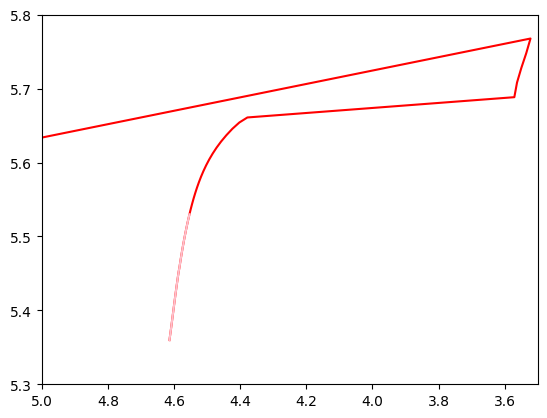

In [60]:
xb=np.array(np.log10(baseline.temperature.value_in(units.K)))
yb=np.array(np.log10(baseline.luminosity.value_in(units.LSun)))
xf=np.array(np.log10(first_part.temperature.value_in(units.K)))
yf=np.array(np.log10(first_part.luminosity.value_in(units.LSun)))
plt.plot(xb,yb,color='red')
plt.plot(xf,yf,color='pink')
plt.xlim(5,3.5)
plt.ylim(5.3,5.8)

Now we want to start at the end of the pink line and evolve further. The star has lost some mass to winds at this point, so we need to reduce its mass. We also want to mimic what Torch does on restart, which is to have the relative age track how far the star has evolved already, and let SeBa choose its starting time (which is equivalent here to setting t_start=0)

In [61]:
new_mass = new_mass=first_part[-1].mass.value_in(units.MSun)  #The new mass is the mass in the last snapshot of the first part of the evolution

print(new_mass)

test_torch=evolve_star(mass=new_mass,relative_mass=40,stellar_type=1,age=3,relative_age=3,core_mass=0,COcore_mass=0,t_start=0,t_end=6,t_step=0.1)


39.0850392033


(5.3, 5.8)

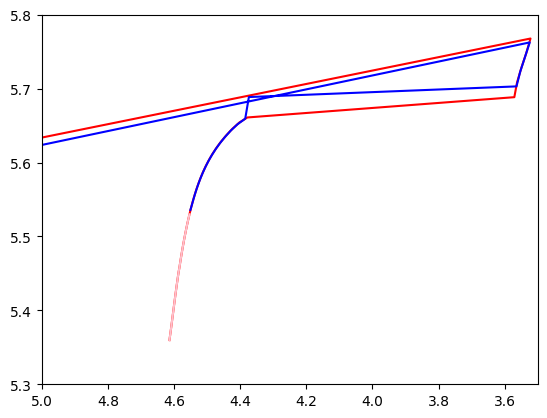

In [62]:
xt=np.array(np.log10(test_torch.temperature.value_in(units.K)))
yt=np.array(np.log10(test_torch.luminosity.value_in(units.LSun)))

plt.plot(xb,yb,color='red')
plt.plot(xf,yf,color='pink')
plt.plot(xt,yt,color='blue')
plt.xlim(5,3.5)
plt.ylim(5.3,5.8)

This test (in blue) does indeed pick up right at the end of the pink line, and follows the main sequence evolution. But when the stellar type changes, suddenly there's a jump in the evolution and the remnant mass is slightly different.

In [63]:
print(baseline.age[-1], test_torch.age[-1]) 
print(baseline.mass[-1], test_torch.mass[-1]) 

6.1 Myr 6.1 Myr
12.6327321903 MSun 11.3298456076 MSun


This evolution does not change if I change any of the following parameters of the initial star:
* age
* relative mass
* core mass
* CO core mass
* radius

Changing the mass moves the track up/down in the ways that you expect.

I did limited testing with the stellar type, but setting it to type 4 at 3 Myr (and not changing the core mass) did not change the evolution of the star. 

I *can* produce a track which starts at 3 Myr and exactly follows the baseline track. However, what I need to do here is set relative_age to zero, t_start to 3 Myr, AND the mass to the initial mass of 40 MSun. Then, as far as I can tell, SeBa silently evolves the star from the ZAMS until the age I want, and then starts producing snapshots. This may be why Josh originally had SeBa evolve each star from t=0 to the current time step in old versions of Torch. We had to change this behaviour when Claude was doing her binary evolution models because of the dynamical modification of the population. 

In [64]:
working_restart=evolve_star(mass=40,relative_mass=0,stellar_type=1,age=3,relative_age=0,core_mass=0,COcore_mass=0,t_start=3,t_end=6,t_step=0.1)


(5.3, 5.8)

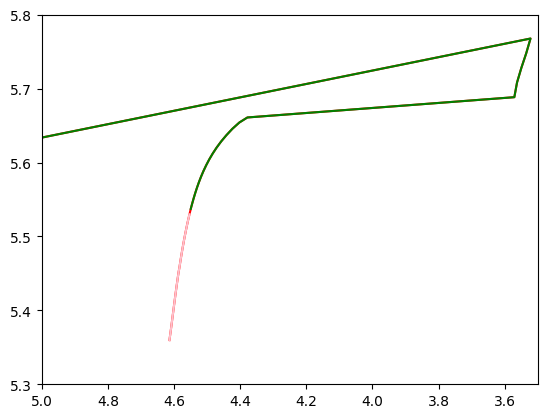

In [65]:
xw=np.array(np.log10(working_restart.temperature.value_in(units.K)))
yw=np.array(np.log10(working_restart.luminosity.value_in(units.LSun)))

plt.plot(xb,yb,color='red')
plt.plot(xf,yf,color='pink')
plt.plot(xw,yw,color='green')
plt.xlim(5,3.5)
plt.ylim(5.3,5.8)

But if we must set the relative age to 0 and we cannot specify t_start, then of course the evolution will begin at the ZAMS. 

In [66]:
working_restart_no_tstart=evolve_star_no_tstart(mass=40,relative_mass=0,stellar_type=1,age=3,relative_age=0,core_mass=0,COcore_mass=0,t_end=6,t_step=0.1)


(5.3, 5.8)

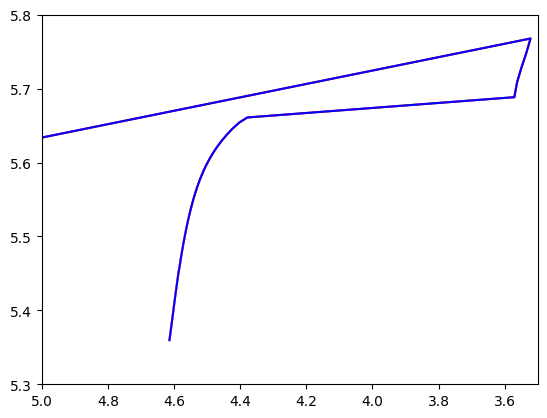

In [67]:
xw_nt=np.array(np.log10(working_restart_no_tstart.temperature.value_in(units.K)))
yw_nt=np.array(np.log10(working_restart_no_tstart.luminosity.value_in(units.LSun)))

plt.plot(xb,yb,color='red')
plt.plot(xf,yf,color='pink')
plt.plot(xw_nt,yw_nt,color='blue')
plt.xlim(5,3.5)
plt.ylim(5.3,5.8)

The Torch-equivalent version (relative age = 3 Myr, t_start=0 or equivalently no t_start specified) does most of what we want but has some deviation from the right answer in the late stages of stellar evolution. Claude did some tests of SeBa on restart and when including the binary evolution/feedback. What she saw was that the evolution after restart was consistent with the evolution before, and that at a population level stars left the main sequence at the right place in the HR diagram and at times that she expected. Those conclusions are reproduced here -- the main sequence evolution is continuous, and the evolution after the main sequence is slightly offset from the correct answer but not by a lot. 

We might decide this is good enough, especially since we know there are already uncertainties in the evolution of massive stars which may be larger than these differences. However, I don't understand why the post-MS evolution has this jump. I have currently only tested this one mass and time of restart. Some more investigation may be needed, by someone who understands SeBa better than I do. 

One final note: one of Edwin's earlier attempts had stars going supernova immediately after they were put back into the code. I can reproduce that behaviour by setting BOTH the relative age and t_start to 3 Myr for our 40 Sun star. 

In [74]:
make_bh=evolve_star(mass=new_mass,relative_mass=40,stellar_type=1,age=3,relative_age=3,core_mass=0,COcore_mass=0,t_start=3,t_end=6,t_step=0.1)

print(make_bh.mass,make_bh.stellar_type)

[12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579, 12.8813521579] MSun [14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14] stellar_type


Based on what we saw above, setting t_start to anything other than 0 means that SeBa evolves the object for that amount of time silently, and then starts producing snapshots. Only one of relative_age or t_start can be set to the advanced age, and which one you choose produces a slightly different evolution for the star. 